Fantastic! I checked the CSV you uploaded, and everything looks correct. 🎉

Milestone completed

Your processed dataset has:

| Property         | Result |
| ---------------- | ------ |
| Records          | 50,000 |
| Features         | 12     |
| Target variables | 1      |
| Partition column | 1      |
| Missing values   | 0      |
| Total columns    | 14     |

The original train/validation/test partitions have also been preserved.

## **Step 12. Separate the three datasets**

Now let's do something simple but important: create separate DataFrames for training, validation, and testing.

Add this to `exploration.py`:


In [4]:
import pandas as pd

df = pd.read_csv("data/processed/oc_risk50k_selected.csv")

train_df = df[df["Partition"] == "Train"].copy()
val_df = df[df["Partition"] == "Validation"].copy()
test_df = df[df["Partition"] == "Test"].copy()

X_train = train_df.drop(columns=["Ovarian_Cancer_Status", "Partition"])
y_train = train_df["Ovarian_Cancer_Status"]

X_val = val_df.drop(columns=["Ovarian_Cancer_Status", "Partition"])
y_val = val_df["Ovarian_Cancer_Status"]

X_test = test_df.drop(columns=["Ovarian_Cancer_Status", "Partition"])
y_test = test_df["Ovarian_Cancer_Status"]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (34946, 12) (34946,)
Validation: (7523, 12) (7523,)
Test: (7531, 12) (7531,)


Perfect! Everything matches our expectations.

Milestone completed

We now have three separate datasets:

- Training: 34,946 patients
- Validation: 7,523 patients
- Testing: 7,531 patients

And each has exactly 12 input features.

## **Step 13. Prepare for discretization**

Now we're approaching our first Bayesian Network-specific task.

Remember, Bayesian Networks can work with continuous variables, but we're initially using `pgmpy`'s discrete Bayesian Network implementation. So we'll convert continuous variables into categories.

For example:

| Age | Category    |
| --- | ----------- |
| 25  | Young       |
| 42  | Middle-aged |
| 58  | Older       |
| 75  | Elderly     |

These boundaries are just illustrative. We haven't decided on the actual thresholds yet!

### **First, let's inspect the distributions in the training set**

Add this to `main.py`:

In [5]:
print("\nAge distribution:")
print(X_train["Age"].describe())

print("\nBMI distribution:")
print(X_train["BMI"].describe())

print("\nParity distribution:")
print(X_train["Parity"].value_counts())


Age distribution:
count    34946.000000
mean        57.979723
std         12.103963
min         18.000000
25%         50.000000
50%         58.200000
75%         66.200000
max         90.000000
Name: Age, dtype: float64

BMI distribution:
count    34946.000000
mean        26.278318
std          5.292269
min         16.000000
25%         22.500000
50%         25.800000
75%         29.500000
max         50.000000
Name: BMI, dtype: float64

Parity distribution:
Parity
1    10386
2     9429
0     5728
3     5604
4     2528
5      923
6      264
7       66
8       18
Name: count, dtype: int64


Great! Now we have enough information to make our first preprocessing decisions.

Let's take a look at what we've learned.

## **1. Age**

Training set: 34,946 patients

| Statistic       | Age  |
| --------------- | ---- |
| Minimum         | 18   |
| 25th percentile | 50   |
| Median          | 58.2 |
| 75th percentile | 66.2 |
| Maximum         | 90   |

Age has a fairly broad distribution. I suggest dividing it into **four categories using quartiles**.

The advantage is that each category will contain approximately 25% of the training observations.

## **2. BMI**

| Statistic       | BMI  |
| --------------- | ---- |
| Minimum         | 16   |
| 25th percentile | 22.5 |
| Median          | 25.8 |
| 75th percentile | 29.5 |
| Maximum         | 50   |

We can initially use the same quartile-based approach.

An alternative would be to use established clinical BMI categories. We can consider that later as an additional experiment.

## **3. Parity**

This one is interesting:

| Number of births | Patients |
| ---------------- | -------- |
| 0                | 5,728    |
| 1                | 10,386   |
| 2                | 9,429    |
| 3                | 5,604    |
| 4                | 2,528    |
| 5                | 923      |
| 6                | 264      |
| 7                | 66       |
| 8                | 18       |

I suggest grouping parity into five categories:

- 0
- 1
- 2
- 3
- 4 or more

Why? Because having separate categories for 7 and 8 would create very sparsely populated states in our Bayesian Network.

## **Step 14. Let's calculate our discretization boundaries**

Before actually transforming anything, let's calculate the quartile boundaries from the training data.

Add this to `main.py`:

In [6]:
for col in ["Age", "BMI"]:
    _, boundaries = pd.qcut(X_train[col], q=4, retbins=True, duplicates="drop")
    print(f"\n{col} boundaries:")
    print(boundaries)


Age boundaries:
[18.  50.  58.2 66.2 90. ]

BMI boundaries:
[16.  22.5 25.8 29.5 50. ]


We'll discretize three features:

- **Age:** 4 categories, using quartiles.
- **BMI:** 4 categories, using quartiles.
- **Parity:** 5 categories: 0, 1, 2, 3, and 4+.

We'll use the boundaries calculated from the training set only.

## **Step 14. Implement discretization**

Add the following code to `main.py`, after your train/validation/test DataFrames have been created.

In [7]:
age_bins = [18, 50, 58.2, 66.2, 90]
age_labels = ["Young", "Middle", "Older", "Elderly"]

bmi_bins = [16, 22.5, 25.8, 29.5, 50]
bmi_labels = ["Low", "Normal", "High", "Very High"]

for dataset in [X_train, X_val, X_test]:
    dataset["Age"] = pd.cut(dataset["Age"], bins=age_bins,
                            labels=age_labels, include_lowest=True)
    dataset["BMI"] = pd.cut(dataset["BMI"], bins=bmi_bins,
                            labels=bmi_labels, include_lowest=True)
    dataset["Parity"] = pd.cut(dataset["Parity"], bins=[-1, 0,
                               1, 2, 3, float("inf")], labels=["0", "1", "2", "3", "4+"])

print("Discretization complete!")

print("\nTraining data:")
print(X_train.head())

Discretization complete!

Training data:
       Age  Menopausal_Status  Family_History  BRCA1_Status  BRCA2_Status  \
0   Middle                  1               0             0             0   
1  Elderly                  1               1             0             0   
2   Middle                  1               1             0             0   
5    Young                  0               0             0             0   
7  Elderly                  1               0             1             0   

   Lynch_Syndrome_Status        BMI Parity  Oral_Contraceptive_History  \
0                      0  Very High      3                           1   
1                      0        Low      2                           0   
2                      0     Normal      3                           0   
5                      0       High      0                           1   
7                      0  Very High      1                           0   

   Endometriosis_History  Hormone_Therapy_History  

### **A quick explanation**

`pd.cut()` assigns each observation to a category according to the boundaries we specify.

For example:

| Age | New category |
| --- | ------------ |
| 25  | Young        |
| 52  | Middle       |
| 60  | Older        |
| 75  | Elderly      |

For Parity, we group all observations with four or more births together. This avoids creating categories with very few observations, such as parity 7 and 8.

**One important detail:** These are quartile-based statistical categories, not established clinical age or BMI thresholds. We'll describe them accurately in the report.

## **Step 15. Verify the results**

Add this immediately afterward:

In [8]:
for col in ["Age", "BMI", "Parity"]:
    print(f"\n{col} distribution:")
    print(X_train[col].value_counts().sort_index())

print("\nMissing values after discretization:")
print(X_train[["Age", "BMI", "Parity"]].isnull().sum())


Age distribution:
Age
Young      8800
Middle     8698
Older      8766
Elderly    8682
Name: count, dtype: int64

BMI distribution:
BMI
Low          8905
Normal       8736
High         8707
Very High    8598
Name: count, dtype: int64

Parity distribution:
Parity
0      5728
1     10386
2      9429
3      5604
4+     3799
Name: count, dtype: int64

Missing values after discretization:
Age       0
BMI       0
Parity    0
dtype: int64


Excellent! **The discretization worked exactly as intended.** No missing values were introduced, and the distributions look reasonable.

A few observations:

- **Age:** The four bins are almost perfectly balanced, as expected from quartile-based discretization.
- **BMI:** Also roughly balanced across four bins.
- **Parity:** The `4+` category combines all higher parity values, giving us five categories without creating tiny groups for values 5–8.

One small thing: your output displays `Very High` rather than `Very_High`. That's just how the label appears in your code/output; either is fine as long as you're consistent.

### **Next step: discretize the remaining categorical features**

Actually, all the other 9 features are already binary (0/1), so **we don't need to discretize them**. Our dataset is now entirely categorical, which is what we'll need for the discrete Bayesian Network.

Let's verify that all columns have the expected data types. Add this to `main.py`:

In [9]:
print("\nFeature data types:")
print(X_train.dtypes)

print("\nTarget distribution:")
print(y_train.value_counts())


Feature data types:
Age                           category
Menopausal_Status                int64
Family_History                   int64
BRCA1_Status                     int64
BRCA2_Status                     int64
Lynch_Syndrome_Status            int64
BMI                           category
Parity                        category
Oral_Contraceptive_History       int64
Endometriosis_History            int64
Hormone_Therapy_History          int64
Tubal_Ligation_History           int64
dtype: object

Target distribution:
Ovarian_Cancer_Status
0    17513
1    17433
Name: count, dtype: int64


Perfect. Your training data is now in the right format for a **discrete Bayesian Network**:

- 12 categorical input features.
- 3 discretized features: `Age`, `BMI`, and `Parity`.
- 9 binary features, already categorical in meaning.
- Binary target: `Ovarian_Cancer_Status`.
- Training set: 34,946 observations, with a nearly balanced target distribution.

One minor technical detail: pandas stores the binary features as `int64`, rather than `category`. That's fine for now, but `pgmpy` will benefit from treating them explicitly as categorical variables.

### **Next step: convert binary columns to categorical**

Add this immediately after your discretization code:

In [10]:
binary_features = [
    "Menopausal_Status",
    "Family_History",
    "BRCA1_Status",
    "BRCA2_Status",
    "Lynch_Syndrome_Status",
    "Oral_Contraceptive_History",
    "Endometriosis_History",
    "Hormone_Therapy_History",
    "Tubal_Ligation_History"
]

for dataset in [X_train, X_val, X_test]:
    for col in binary_features:
        dataset[col] = dataset[col].astype("category")

y_train = y_train.astype("category")
y_val = y_val.astype("category")
y_test = y_test.astype("category")

This makes the data types consistent. **Don't change the actual 0/1 values**; they're useful as category labels.

Then print:

In [11]:
print(X_train.dtypes)
print(y_train.dtypes)

Age                           category
Menopausal_Status             category
Family_History                category
BRCA1_Status                  category
BRCA2_Status                  category
Lynch_Syndrome_Status         category
BMI                           category
Parity                        category
Oral_Contraceptive_History    category
Endometriosis_History         category
Hormone_Therapy_History       category
Tubal_Ligation_History        category
dtype: object
category


Let's do it! We'll build our **first manually specified Bayesian Network** using `pgmpy`.

We'll take this one step at a time. Our first model will be a simple Naïve Bayes-style network, which we'll later compare against a more sophisticated network learned from the data.

## **Step 1 — Define the network structure**

Our network will contain:

- 12 input feature nodes.
- 1 outcome node: `Ovarian_Cancer_Status`.
- 12 directed edges, each pointing from the outcome to an input feature.

Why point the arrows *from the outcome*? Because this is a generative Naïve Bayes model: it models the features as conditionally independent given the outcome. We'll still use it to predict the outcome from observed features.

**Our initial network**

**Ovarian_Cancer_Status**

Outcome node

Age

Menopausal_Status

Family_History

BRCA1_Status

BRCA2_Status

Lynch_Syndrome_Status

BMI

Parity

Oral_Contraceptive_History

Endometriosis_History

Hormone_Therapy_History

Tubal_Ligation_History

Conceptual illustration: each feature has an edge from the outcome.

## **Step 2 — Write the code**

Add the following to `main.py`, after your data preparation code:

In [12]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import HillClimbSearch, BayesianEstimator
from pgmpy.inference import VariableElimination

features = list(X_train.columns)
target = "Ovarian_Cancer_Status"
edges = [(target, feature) for feature in features]
model = DiscreteBayesianNetwork(edges)
print("Nodes:", model.nodes())
print("Edges:", model.edges())

/Volumes/Jerry/Source/cs-4710-project-final/venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Nodes: ['Ovarian_Cancer_Status', 'Age', 'Menopausal_Status', 'Family_History', 'BRCA1_Status', 'BRCA2_Status', 'Lynch_Syndrome_Status', 'BMI', 'Parity', 'Oral_Contraceptive_History', 'Endometriosis_History', 'Hormone_Therapy_History', 'Tubal_Ligation_History']
Edges: [('Ovarian_Cancer_Status', 'Age'), ('Ovarian_Cancer_Status', 'Menopausal_Status'), ('Ovarian_Cancer_Status', 'Family_History'), ('Ovarian_Cancer_Status', 'BRCA1_Status'), ('Ovarian_Cancer_Status', 'BRCA2_Status'), ('Ovarian_Cancer_Status', 'Lynch_Syndrome_Status'), ('Ovarian_Cancer_Status', 'BMI'), ('Ovarian_Cancer_Status', 'Parity'), ('Ovarian_Cancer_Status', 'Oral_Contraceptive_History'), ('Ovarian_Cancer_Status', 'Endometriosis_History'), ('Ovarian_Cancer_Status', 'Hormone_Therapy_History'), ('Ovarian_Cancer_Status', 'Tubal_Ligation_History')]


We'll use **Bayesian parameter estimation with a small amount of smoothing** to estimate the CPTs. Smoothing helps prevent probabilities from becoming exactly zero when a particular combination of values doesn't appear in the training data.

## **Step 3 — Estimate the CPTs**

Add this immediately after your network definition:

In [13]:
model.fit(pd.concat([X_train, y_train], axis=1),
          estimator=BayesianEstimator, prior_type="BDeu", equivalent_sample_size=5)
print("\nCPT estimation complete!")

for cpd in model.get_cpds():
    print(f"\n{cpd.variable}")
    print(cpd)


INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Age': 'O', 'Menopausal_Status': 'C', 'Family_History': 'C', 'BRCA1_Status': 'C', 'BRCA2_Status': 'C', 'Lynch_Syndrome_Status': 'C', 'BMI': 'O', 'Parity': 'O', 'Oral_Contraceptive_History': 'C', 'Endometriosis_History': 'C', 'Hormone_Therapy_History': 'C', 'Tubal_Ligation_History': 'C', 'Ovarian_Cancer_Status': 'C'}



CPT estimation complete!

Ovarian_Cancer_Status
+--------------------------+----------+
| Ovarian_Cancer_Status(0) | 0.501144 |
+--------------------------+----------+
| Ovarian_Cancer_Status(1) | 0.498856 |
+--------------------------+----------+

Age
+-----------------------+--------------------------+--------------------------+
| Ovarian_Cancer_Status | Ovarian_Cancer_Status(0) | Ovarian_Cancer_Status(1) |
+-----------------------+--------------------------+--------------------------+
| Age(Elderly)          | 0.18775513116953554      | 0.30940466290040436      |
+-----------------------+--------------------------+--------------------------+
| Age(Middle)           | 0.2506137421141275       | 0.24717530326058904      |
+-----------------------+--------------------------+--------------------------+
| Age(Older)            | 0.20608175615883076      | 0.2958117060021221       |
+-----------------------+--------------------------+--------------------------+
| Age(Young)            | 

LOOK AT THAT. We have successfully trained our first Bayesian Network! 🎉

And the CPTs look structurally correct. Let's examine what we've learned before moving forward.

## **1. Sanity check: did parameter estimation work?**

Yes. A few things worth noticing:

- The prior probability of cancer is approximately **49.89%**, matching the training-set distribution.
- Every feature has a conditional probability distribution for both cancer outcomes.
- The probabilities within each outcome column sum to approximately 1.
- We used Bayesian smoothing, so even rare categories have nonzero probabilities.

For example, look at Age:

| Age category | No cancer | Cancer |
| ------------ | --------- | ------ |
| Young        | 35.55%    | 14.76% |
| Middle       | 25.06%    | 24.72% |
| Older        | 20.61%    | 29.58% |
| Elderly      | 18.78%    | 30.94% |

The model has learned that elderly patients are more prevalent in the cancer group in this synthetic dataset.

## **2. Some interesting observations**

A few features show noticeable differences between the two outcome groups:

| Feature                    | Observation                                           |
| -------------------------- | ----------------------------------------------------- |
| BRCA1                      | Positive status is more prevalent in the cancer group |
| BRCA2                      | Positive status is more prevalent in the cancer group |
| Family history             | More prevalent in the cancer group                    |
| Oral contraceptive history | More prevalent in the non-cancer group                |
| Tubal ligation history     | More prevalent in the non-cancer group                |
| BMI                        | Almost identical distributions                        |
| Parity                     | Almost identical distributions                        |

These are associations in our synthetic benchmark, not evidence of real-world clinical effects.

## **3. One important limitation**

Our current network assumes:

\\[ X_i \perp X_j \mid Y \\]

In other words, given the cancer outcome, every feature is assumed conditionally independent of every other feature.

For example, it assumes that Age and Menopausal Status are conditionally independent given cancer status.

That is a simplifying assumption of Naïve Bayes. It may not accurately represent real relationships between clinical variables.

This is precisely why we'll eventually compare it with a data-driven Bayesian Network.

## **4. Next step: make predictions!**

Now comes the fun part. We'll use **Variable Elimination** to calculate the probability of cancer for each patient based on their observed features.

Add this after your CPT estimation code:

In [14]:
inference = VariableElimination(model)
evidence = X_test.iloc[0].to_dict()
prediction = inference.query(variables=["Ovarian_Cancer_Status"], evidence=evidence)
print("\nExample patient:")
print(evidence)
print("\nPredicted probabilities:")
print(prediction)


Example patient:
{'Age': 'Elderly', 'Menopausal_Status': 1, 'Family_History': 0, 'BRCA1_Status': 0, 'BRCA2_Status': 0, 'Lynch_Syndrome_Status': 0, 'BMI': 'Normal', 'Parity': '0', 'Oral_Contraceptive_History': 0, 'Endometriosis_History': 0, 'Hormone_Therapy_History': 0, 'Tubal_Ligation_History': 0}

Predicted probabilities:
+--------------------------+------------------------------+
| Ovarian_Cancer_Status    |   phi(Ovarian_Cancer_Status) |
+==========================+==============================+
| Ovarian_Cancer_Status(0) |                       0.3841 |
+--------------------------+------------------------------+
| Ovarian_Cancer_Status(1) |                       0.6159 |
+--------------------------+------------------------------+


IT WORKS!! 😂🎉

We've successfully performed inference on an actual test-set patient.

Let's interpret the result:

**Example patient's predicted probabilities**

No cancer (0)

**38.41%**

Cancer (1)

**61.59%**

Predicted class: 1 (Cancer)

The model estimates:

\\[ P(Y=1\mid X_1,\ldots,X\_{12})=0.6159 \\]

In other words, given this patient's recorded features, our model assigns a 61.59% probability to the cancer outcome.

Notice something interesting: this patient has no recorded family history, BRCA1/2 mutations, or Lynch syndrome, but the model still predicts a probability above 50%. Age and menopausal status, among other features, contribute to the estimate.

**Important:** This is a prediction from a synthetic benchmark, not a real clinical risk assessment.

## **Next step: predict the entire test set**

One patient is a nice demonstration, but we need to evaluate all 7,531 test observations.

Replace the single-patient inference snippet with this:

In [15]:
y_pred_proba = []

for _, patient in X_test.iterrows():
    evidence = patient.to_dict()
    prediction = inference.query(variables=["Ovarian_Cancer_Status"], evidence=evidence, show_progress=False)
    cancer_probability = prediction.values[1]
    y_pred_proba.append(cancer_probability)

print("Predictions completed!")
print("Number of predictions:", len(y_pred_proba))
print("First 5 probabilities:", y_pred_proba[:5])

Predictions completed!
Number of predictions: 7531
First 5 probabilities: [np.float64(0.6159105078070952), np.float64(0.4920475957819168), np.float64(0.6299714031576152), np.float64(0.8402710680173365), np.float64(0.9334480193137158)]


YES! All **7,531 test-set predictions completed successfully**. 🎉

And the probabilities look reasonable: we're getting a range of predictions rather than the same probability for every patient.

Now we can finally evaluate our first model.

## **Step 4 — Evaluate predictive performance**

Your professor specifically requested three metrics:

1. **AUROC:** How well does the model distinguish cancer from non-cancer cases?
2. **Precision-Recall:** How well does it identify positive cases, particularly when considering false positives?
3. **Brier Score:** How accurate are the predicted probabilities?

Let's calculate them.

Add this after your prediction loop:

In [16]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

auc = roc_auc_score(y_test.astype(int), y_pred_proba)
pr_auc = average_precision_score(y_test.astype(int), y_pred_proba)
brier = brier_score_loss(y_test.astype(int), y_pred_proba)

print("\nBayesian Network Evaluation:")
print("----------------------------")
print(f"AUROC:       {auc:.4f}")
print(f"PR-AUC:      {pr_auc:.4f}")
print(f"Brier Score: {brier:.4f}")


Bayesian Network Evaluation:
----------------------------
AUROC:       0.8296
PR-AUC:      0.8457
Brier Score: 0.1696


WAIT. An AUROC of 0.8296 for our first manually specified Bayesian Network? That's a pretty encouraging result! 😭

We've gone from a raw CSV to a functioning probabilistic model, and it's showing meaningful predictive performance on previously unseen test data.
1. Our first model's results
0.8296
AUROC

Ability to distinguish cancer from non-cancer observations

0.8457
PR-AUC

Precision-recall performance

0.1696
Brier Score

Mean squared probability error



A quick interpretation:
- AUROC 0.8296: The model has good discrimination. It can distinguish positive and negative cases substantially better than random ranking.
- PR-AUC 0.8457: Also encouraging. Since our test set is approximately balanced, this is meaningfully above the approximately 0.5 random-ranking baseline.
- Brier Score 0.1696: The probability predictions have some predictive value, although we still need to examine calibration.
2. What does this mean for our project?
Remember, our research proposal compares three approaches:
Model	Status
Manually specified Bayesian Network	Completed
Data-driven Bayesian Network	Not started
Logistic Regression	Not started

Our first model is our initial benchmark.

However, I want to emphasize something: we shouldn't conclude that this model is clinically accurate. We're evaluating performance on a synthetic dataset, and the results only tell us how well it learns patterns in this particular benchmark.
3. One more evaluation: calibration
Your professor explicitly requested calibration evaluation.

A model can have a good AUROC but still systematically overestimate or underestimate probabilities.

Let's start by generating a calibration curve.

Add these imports:

In [17]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

Then add:

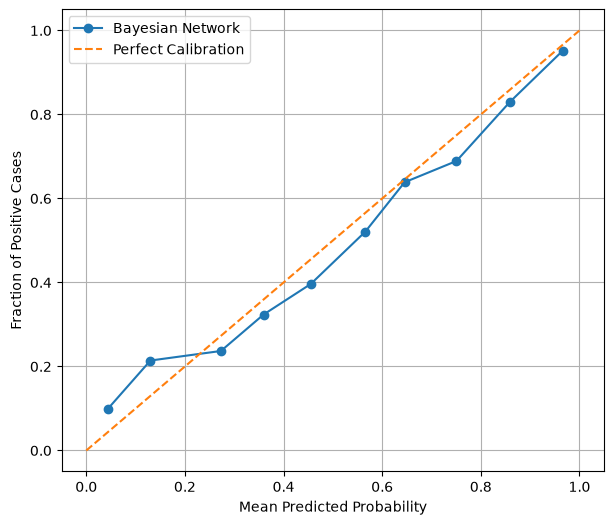

In [18]:
fraction_positive, mean_predicted = calibration_curve(
    y_test.astype(int),
    y_pred_proba,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(7, 6))
plt.plot(mean_predicted, fraction_positive, marker="o", label="Bayesian Network")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positive Cases")
plt.legend()
plt.grid(True)
plt.savefig("bayesian_network_calibration.png", dpi=300)
plt.show()

The closer our curve is to the diagonal, the better calibrated our model is.

Send me the plot (or describe its shape), and we'll interpret it.

**And please save those three evaluation numbers somewhere.** They're our first actual experimental results, and we'll need them when comparing the other two models.

Yes, exactly! Those are the three evaluation numbers I meant:

1. **AUROC:** 0.8296
2. **PR-AUC:** 0.8457
3. **Brier Score:** 0.1696

We'll preserve all three for our final comparison against the data-driven Bayesian Network and logistic regression.

## **About your calibration curve**

I looked at your screenshot. Overall, this is a pretty encouraging result!

Here's how to interpret it:

- **Below the diagonal:** The model tends to overestimate probabilities.
- **Above the diagonal:** The model tends to underestimate probabilities.
- **On the diagonal:** Perfect calibration.

Your curve has points on both sides:

- At lower predicted probabilities (roughly 0.1–0.2), the model generally underestimates the observed positive frequency.
- Around 0.3–0.6, it is relatively close to the diagonal.
- Around 0.7–0.8, it overestimates the observed positive frequency.
- At the highest probabilities, it is close to the diagonal again.

So the model is reasonably calibrated overall, but not perfectly.

One caveat: calibration curves depend on binning. With 10 bins, some fluctuations are expected, particularly in bins containing fewer observations.

## **Let's preserve our first results**

I'd like you to add this comment to `main.py` so we have a record:

In [20]:
# ==========================================
# Model 1: Manually Specified Bayesian Network
# ==========================================
# AUROC:       0.8296
# PR-AUC:      0.8457
# Brier Score: 0.1696
#
# Calibration: Reasonably close to the diagonal,
# with some overestimation and underestimation.
# ==========================================

**And that's Model 1 complete!**

**Model 1 – Manually Specified Bayesian Network:** A Naïve Bayes-style model in which ovarian cancer status is the parent node of 12 patient features, assuming conditional independence among those features given the outcome. Its network structure is specified manually, while its conditional probability tables are learned from the training data using Bayesian estimation with BDeu smoothing.

Next, we'll tackle the more interesting experiment: learning the Bayesian Network's structure directly from the training data using Hill Climbing and BIC.

That's where things get a little more exciting. 😁

Let's go! 😁 **Model 2 will be our data-driven Bayesian Network.**

Unlike Model 1, where we manually decided how the nodes connect, Model 2 will let an algorithm discover the network structure from the training data.

We'll use:

- **Hill Climbing** to search for a suitable network structure.
- **BIC (Bayesian Information Criterion)** to score candidate structures and penalize unnecessary complexity.
- **Bayesian parameter estimation with BDeu smoothing** to learn the CPTs after the structure is selected.

The important experimental rule stays the same: **structure learning and parameter estimation will use training data only.** We won't let validation or test data influence the learned network.

## **Step 1 — Learn the network structure**

We'll start Hill Climbing from an empty graph. It will iteratively try adding, removing, and reversing edges, keeping changes that improve the BIC score.&#x20;

[image](https://www.google.com/s2/favicons?domain=https://pgmpy.org\&sz=32)

pgmpy docs+1



### **Add this to&#x20;**`main.py`

Place it after Model 1's evaluation code.

In [21]:
train_data = pd.concat([X_train, y_train], axis=1)

hc = HillClimbSearch(train_data)

best_dag = hc.estimate(
    scoring_method="bic-d",
    max_indegree=3,
    show_progress=True
)

print("\nModel 2 - Learned Network Structure")
print("------------------------------------")
print("Number of nodes:", len(best_dag.nodes()))
print("Number of edges:", len(best_dag.edges()))

print("\nLearned edges:")
for edge in best_dag.edges():
    print(edge)

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Age': 'O', 'Menopausal_Status': 'C', 'Family_History': 'C', 'BRCA1_Status': 'C', 'BRCA2_Status': 'C', 'Lynch_Syndrome_Status': 'C', 'BMI': 'O', 'Parity': 'O', 'Oral_Contraceptive_History': 'C', 'Endometriosis_History': 'C', 'Hormone_Therapy_History': 'C', 'Tubal_Ligation_History': 'C', 'Ovarian_Cancer_Status': 'C'}
INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Age': 'O', 'Menopausal_Status': 'C', 'Family_History': 'C', 'BRCA1_Status': 'C', 'BRCA2_Status': 'C', 'Lynch_Syndrome_Status': 'C', 'BMI': 'O', 'Parity': 'O', 'Oral_Contraceptive_History': 'C', 'Endometriosis_History': 'C', 'Hormone_Therapy_History': 'C', 'Tubal_Ligation_History': 'C', 'Ovarian_Cancer_Status': 'C'}
INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Age': 'O', 'Menopausal_Status': 'C', 'Family_


Model 2 - Learned Network Structure
------------------------------------
Number of nodes: 13
Number of edges: 12

Learned edges:
('Age', 'Ovarian_Cancer_Status')
('Menopausal_Status', 'Age')
('Menopausal_Status', 'Hormone_Therapy_History')
('Family_History', 'BRCA1_Status')
('BRCA2_Status', 'Family_History')
('Ovarian_Cancer_Status', 'BRCA1_Status')
('Ovarian_Cancer_Status', 'BRCA2_Status')
('Ovarian_Cancer_Status', 'Oral_Contraceptive_History')
('Ovarian_Cancer_Status', 'Tubal_Ligation_History')
('Ovarian_Cancer_Status', 'Endometriosis_History')
('Ovarian_Cancer_Status', 'Lynch_Syndrome_Status')
('Ovarian_Cancer_Status', 'Family_History')




### **A couple of things to understand**

- `scoring_method="bic-d"`: Uses BIC for discrete variables. It balances how well the structure fits the data against its complexity.
- `max_indegree=3`: Limits each node to at most three parents. This helps keep the network manageable and reduces the risk of excessively large CPTs.
- `show_progress=True`: Displays the search progress.

**Important:** We're including `Ovarian_Cancer_Status` in `train_data`, because we want the algorithm to learn relationships between the predictors and the outcome too.

Also, the learned edge directions represent a statistically selected network structure; they should not automatically be interpreted as causal relationships.

### **Your task**

Run `main.py` and let Hill Climbing finish. It may take a little while, but your M1 MacBook should be able to handle this dataset.

Send me the learned nodes and edges. I'm particularly interested in seeing how different this network looks from our first Naïve Bayes-style model!

Oh, interesting! Model 2 has learned a substantially different structure from Model 1. And the search finished successfully!

## **1. What did Hill Climbing discover?**

Structure learning completed

- Nodes: 13
- Edges: 12
- Maximum allowed indegree: 3
- Search stopped after 13 iterations because it found no further improving edge changes.

Here's how the learned relationships differ from Model 1:

| Model 1                                                        | Model 2                                 |
| -------------------------------------------------------------- | --------------------------------------- |
| Cancer status is the parent of all 12 features                 | Relationships are learned from the data |
| All features are conditionally independent given cancer status | Features can depend on other features   |
| Simple star-shaped network                                     | More complex network structure          |

Some particularly interesting edges:

- `Menopausal_Status → Age`
- `Family_History → BRCA1_Status`
- `BRCA2_Status → Family_History`
- `Age → Ovarian_Cancer_Status`

Notice that `BMI` and `Parity` have no edges. The algorithm found no connection involving these variables that improved its BIC score during the search.

**Important:** These are statistical dependencies selected by the algorithm, not proof of causal relationships.

## **2. Step 2 — Construct and train Model 2**

Now we need to turn the learned structure into an actual Bayesian Network and estimate its CPTs.

There's one important detail: `BMI` and `Parity` are isolated nodes. We must explicitly preserve them when constructing the model.

Add this after your Hill Climbing code:

In [23]:
model2 = DiscreteBayesianNetwork()
model2.add_nodes_from(best_dag.nodes())
model2.add_edges_from(best_dag.edges())
model2.fit(train_data, estimator=BayesianEstimator, prior_type="BDeu", equivalent_sample_size=5)
print("\nModel 2 training complete!")
print("Number of nodes:", len(model2.nodes()))
print("Number of edges:", len(model2.edges()))
print("Number of CPTs:", len(model2.get_cpds()))

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Age': 'O', 'Menopausal_Status': 'C', 'Family_History': 'C', 'BRCA1_Status': 'C', 'BRCA2_Status': 'C', 'Lynch_Syndrome_Status': 'C', 'BMI': 'O', 'Parity': 'O', 'Oral_Contraceptive_History': 'C', 'Endometriosis_History': 'C', 'Hormone_Therapy_History': 'C', 'Tubal_Ligation_History': 'C', 'Ovarian_Cancer_Status': 'C'}



Model 2 training complete!
Number of nodes: 13
Number of edges: 12
Number of CPTs: 11


## **3. Why this step matters**

Hill Climbing learned **how the variables connect**, but it hasn't yet learned their probability distributions.

The `fit()` call estimates those distributions from the training data, just as we did with Model 1.

We'll then use Variable Elimination to predict cancer probabilities and evaluate Model 2 using exactly the same three metrics:

- AUROC
- PR-AUC
- Brier Score

Run this first and send me the output. We're making good progress! 😁

Good catch! The network has **13 nodes but only 11 CPTs**, so something needs investigating before we proceed.

I suspect the two isolated nodes, `BMI` and `Parity`, are involved. Hill Climbing didn't find any edges connected to them, but they still need probability distributions of their own.

In a Bayesian Network, even a node with no parents needs a CPT—in this case, simply its prior probability distribution.

Let's identify exactly what's missing before changing anything.

### **Step 1 — Find the missing CPTs**

Add this after your Model 2 training code:

In [24]:
nodes = set(model2.nodes())
cpd_variables = {cpd.variable for cpd in model2.get_cpds()}

print("\nNodes without CPTs:")
print(nodes - cpd_variables)

print("\nNodes with CPTs:")
print(cpd_variables)


Nodes without CPTs:
{'Parity', 'BMI'}

Nodes with CPTs:
{'Oral_Contraceptive_History', 'BRCA1_Status', 'Tubal_Ligation_History', 'Hormone_Therapy_History', 'Lynch_Syndrome_Status', 'Age', 'Endometriosis_History', 'Menopausal_Status', 'Ovarian_Cancer_Status', 'BRCA2_Status', 'Family_History'}


Exactly as suspected! Both missing CPTs belong to isolated nodes:

- `BMI`
- `Parity`

This is actually a useful discovery: **every node in a Bayesian Network needs a CPT, even if it has no parents.** For an isolated node, that CPT is simply its marginal probability distribution:

\\[ P(BMI), \qquad P(Parity) \\]

### **Why did this happen?**

`pgmpy`'s `fit()` estimated CPTs for the connected part of the network, but didn't automatically create CPTs for these isolated nodes in this situation.

Let's add them explicitly using `BayesianEstimator`.

### **Fix**

Add this immediately after your existing `model2.fit(...)`:

In [25]:
model2 = DiscreteBayesianNetwork()
model2.add_nodes_from(best_dag.nodes())
model2.add_edges_from(best_dag.edges())
model2.fit(train_data, estimator=BayesianEstimator, prior_type="BDeu", equivalent_sample_size=5)
isolated_nodes = ["BMI", "Parity"]

for node in isolated_nodes:
    estimator = BayesianEstimator(model2, train_data)
    cpd = estimator.estimate_cpd(node, prior_type="BDeu", equivalent_sample_size=5)
    model2.add_cpds(cpd)

print("\nModel 2 training complete!")
print("Number of nodes:", len(model2.nodes()))
print("Number of edges:", len(model2.edges()))
print("Number of CPTs:", len(model2.get_cpds()))



INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Age': 'O', 'Menopausal_Status': 'C', 'Family_History': 'C', 'BRCA1_Status': 'C', 'BRCA2_Status': 'C', 'Lynch_Syndrome_Status': 'C', 'BMI': 'O', 'Parity': 'O', 'Oral_Contraceptive_History': 'C', 'Endometriosis_History': 'C', 'Hormone_Therapy_History': 'C', 'Tubal_Ligation_History': 'C', 'Ovarian_Cancer_Status': 'C'}
INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Age': 'O', 'Menopausal_Status': 'C', 'Family_History': 'C', 'BRCA1_Status': 'C', 'BRCA2_Status': 'C', 'Lynch_Syndrome_Status': 'C', 'BMI': 'O', 'Parity': 'O', 'Oral_Contraceptive_History': 'C', 'Endometriosis_History': 'C', 'Hormone_Therapy_History': 'C', 'Tubal_Ligation_History': 'C', 'Ovarian_Cancer_Status': 'C'}


NetworkXError: The node BMI is not in the digraph.